# Assignment 2: Developing an End-to-End Machine Learning System
**Course:** AIC354 — Machine Learning Fundamentals  
**University:** COMSATS University Islamabad, Lahore Campus  
**Student:** Waniya Farooq *(edit if needed)*

> **Deployment link:** Add your actual public app URL here after deploying.  
> This notebook provides a complete workflow for Task 2 (Heart Disease Prediction) and a checklist for Task 1 (Titanic). Run the cells from top to bottom.

## Assignment objectives
- Load and understand structured data.
- Preprocess data and encode the target label.
- Train and evaluate a classification model.
- Save the trained model.
- Prepare the model for cloud deployment.

**Important:** The assignment requires only four input attributes for the heart-disease model. This solution uses `age`, `sex`, `cp` (chest-pain type), and `thalach` (maximum heart rate). The target is converted to two classes: `0 = no disease`, `1 = disease present`. This is an educational model, not a medical diagnostic tool.


## 1. Install and import libraries

If an import fails, install the missing package in your notebook environment. The deployment app uses Streamlit separately.

In [4]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement seaborn (from versions: none)
ERROR: No matching distribution found for seaborn


In [8]:
import sys

!{sys.executable} -m pip install --trusted-host pypi.org --trusted-host files.pythonhosted.org seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score
)
from sklearn.dummy import DummyClassifier
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


## 2. Collect the Heart Disease dataset

The source is the UCI Heart Disease dataset. The Cleveland file contains 303 records. Missing values are represented by `?`, so they are converted to `NaN` during loading.

In [7]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

try:
    df = pd.read_csv(url, names=columns, na_values="?")
except Exception as e:
    raise RuntimeError(
        "Could not download the UCI dataset. Check your internet connection, "
        "or download processed.cleveland.data from the UCI Heart Disease dataset "
        "and load it with pd.read_csv('processed.cleveland.data', names=columns, na_values='?')."
    ) from e

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 3. Understand and inspect the data

Check column types, missing values, descriptive statistics, and the distribution of the target. In the original dataset, `num` ranges from 0 to 4. For this binary classifier, values above 0 mean disease is present.

In [8]:
display(df.info())
display(df.describe(include="all").T)
print("Missing values per column:")
display(df.isna().sum().sort_values(ascending=False))


<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


None

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


Missing values per column:


ca          4
thal        2
cp          0
trestbps    0
age         0
sex         0
fbs         0
chol        0
restecg     0
thalach     0
oldpeak     0
exang       0
slope       0
num         0
dtype: int64

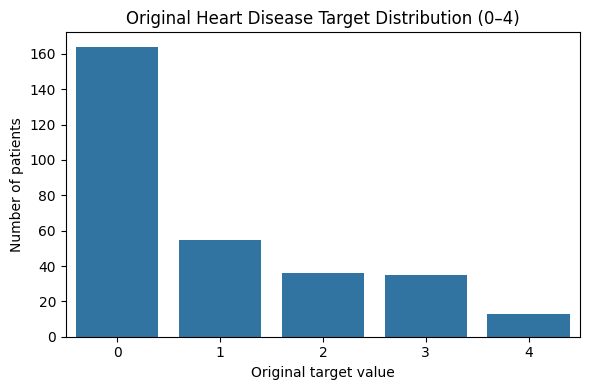

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="num")
plt.title("Original Heart Disease Target Distribution (0–4)")
plt.xlabel("Original target value")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.show()


## 4. Data preprocessing and label encoding

Only four input attributes are used, as required by the assignment:
- `age`: age in years
- `sex`: dataset coding (1 = male, 0 = female)
- `cp`: chest-pain type code
- `thalach`: maximum heart rate achieved

The target is `1` if the original `num` value is greater than 0; otherwise it is `0`. Missing feature values are imputed using the median inside the pipeline, preventing information leakage from the test set.

In [10]:
features = ["age", "sex", "cp", "thalach"]
X = df[features].copy()
y = (df["num"] > 0).astype(int)

print("Selected input features:", features)
print("\nTarget counts (0 = no disease, 1 = disease present):")
display(y.value_counts().rename_axis("target").to_frame("count"))
print("\nMissing values in selected features:")
display(X.isna().sum())


Selected input features: ['age', 'sex', 'cp', 'thalach']

Target counts (0 = no disease, 1 = disease present):


,count
target,
0,164
1,139



Missing values in selected features:


age        0
sex        0
cp         0
thalach    0
dtype: int64

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 242
Testing rows: 61


## 5. Train the machine learning model

A pipeline performs median imputation, feature scaling, and logistic regression. Scaling is useful because the selected features have different numeric ranges.

In [12]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

model.fit(X_train, y_train)
print("Model training completed.")


Model training completed.


## 6. Evaluate the model

Accuracy is the proportion of correct predictions. The classification report gives precision, recall, and F1-score for each class. The confusion matrix shows correct and incorrect predictions. Results can vary slightly if the split or model settings are changed.

In [13]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease present"], zero_division=0))

try:
    print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")
except ValueError:
    print("ROC-AUC could not be calculated for this split.")


Test accuracy: 0.787

Classification report:
                 precision    recall  f1-score   support

     No disease       0.78      0.85      0.81        33
Disease present       0.80      0.71      0.75        28

       accuracy                           0.79        61
      macro avg       0.79      0.78      0.78        61
   weighted avg       0.79      0.79      0.79        61

ROC-AUC: 0.856


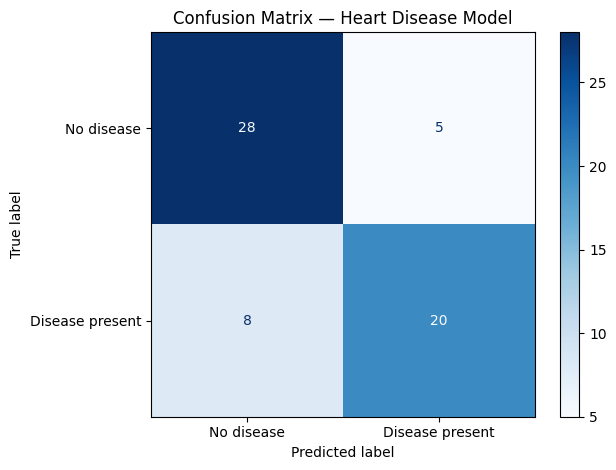

In [14]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No disease", "Disease present"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Heart Disease Model")
plt.tight_layout()
plt.show()


### Results and discussion

After running the notebook, record the displayed test accuracy, precision, recall, F1-score, and ROC-AUC here. Do not write guessed values: they depend on the dataset download and the executed train/test split.

The model learns a relationship between the four selected attributes and the binary target. A single accuracy score is not enough to assess a health-related classifier; recall for the disease-present class is also important because false negatives may be consequential. This small, historical dataset may not represent current or diverse patient populations, and predictions must not be used for real medical decisions.

## 7. Predict for a new sample

Enter values in the same format as the dataset. The example below is only a demonstration; it is not a real patient's assessment.

In [15]:
sample = pd.DataFrame([{
    "age": 50,
    "sex": 1,
    "cp": 2,
    "thalach": 150
}])[features]

prediction = int(model.predict(sample)[0])
probability = float(model.predict_proba(sample)[0, 1])

print("Predicted class:", prediction, "(1 = disease present, 0 = no disease)")
print(f"Estimated probability for class 1: {probability:.1%}")
print("Educational demonstration only — not medical advice or a diagnosis.")


Predicted class: 0 (1 = disease present, 0 = no disease)
Estimated probability for class 1: 31.0%
Educational demonstration only — not medical advice or a diagnosis.


## 8. Save the trained model

The saved file includes the preprocessing steps and classifier together, so the same transformations are applied later in the web app.

In [16]:
model_path = "heart_disease_model.joblib"
joblib.dump(model, model_path)
print(f"Saved model to: {model_path}")


Saved model to: heart_disease_model.joblib


## 9. Load the saved model and verify it

This checks that the exported model can be loaded and produces the same prediction for the demonstration sample.

In [17]:
loaded_model = joblib.load(model_path)
loaded_prediction = int(loaded_model.predict(sample)[0])
print("Prediction from original model:", prediction)
print("Prediction from loaded model:", loaded_prediction)
assert prediction == loaded_prediction
print("Model save/load verification passed.")


Prediction from original model: 0
Prediction from loaded model: 0
Model save/load verification passed.


## 10. Deploy the model as a public web app

This assignment asks for a cloud deployment link at the very top of the notebook. The included `app.py` file can be deployed to Streamlit Community Cloud:
1. Run all notebook cells and make sure `heart_disease_model.joblib` is created.
2. Put `app.py`, `heart_disease_model.joblib`, and `requirements.txt` in a GitHub repository.
3. Open Streamlit Community Cloud, sign in, choose **Create app**, and select that repository and `app.py`.
4. Deploy and test the public URL.
5. Paste your real URL into the Deployment link line at the top of this notebook.

Do not paste a made-up URL: the public link only exists after deployment. If your instructor specifically requires PythonAnywhere, follow the provided PythonAnywhere tutorial and adapt the same model/app files to that platform.

## 11. Task 1 — Titanic Passenger Survival Prediction System checklist

The assignment says the instructor-provided Titanic notebook/code is available locally. That code was not included with the assignment PDF, so its exact cells and results cannot be reproduced from the PDF alone.

Complete Task 1 using the provided Titanic notebook:
1. Open the instructor's `Titanic_Passenger_Survival_FullEnhancement.ipynb` (or the exact notebook supplied locally).
2. Run all cells from top to bottom and inspect data loading, preprocessing, encoding, training, and evaluation.
3. Complete the instructor's Step 10 deployment instructions.
4. Deploy the trained Titanic model to the cloud and test the public link.
5. Add the real Titanic deployment URL at the top of your submission notebook.

If you need both tasks in one submission, keep this notebook for Task 2 and include the instructor's completed Titanic notebook as the Task 1 deliverable, with the live deployment link in each notebook.

## Conclusion

This notebook follows an end-to-end machine learning workflow: data collection, data understanding, preprocessing, label encoding, train/test splitting, model training, evaluation, sample prediction, model export, and deployment preparation. The heart-disease model uses exactly four input attributes as required.

**Before submission:** Run every cell, check the output, include the generated model file, add your actual cloud deployment URL, and include the completed Titanic notebook/code and its deployment link.